# Synthetic fibril: kink and sausage waves
Each exercise is split into **blocks**: one cell each. The boring parts (loading, plots, GIFs) live in `tools.py`, which is imported as a package from your Google Drive folder (set `FOLDER` in the first cell). Run the cells in order.

### Setup

In [1]:
# Mount Google Drive and work inside YOUR folder (where tools.py and the cube are).
FOLDER = "/content/drive/MyDrive/HelioData_MHD_Modes/Codes"
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(FOLDER)
except ImportError:
    pass                                       # not in Colab: run from the current folder
sys.path.insert(0, os.getcwd())
!pip -q install astropy pillow
import tools as tl                             #  the toolbox, used as a package
# the cube can be in FOLDER/data/ or directly in FOLDER
if not os.path.exists(os.path.join(tl.DATA, "fibril_cube.fits")) and os.path.exists("fibril_cube.fits"):
    tl.DATA = "."
print("working in", os.getcwd(), "| tools loaded | cube folder:", tl.DATA)
print(sorted(os.listdir(".")))


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
working in /home/oscar/Escuela-Astrofisica-Solar-2026/01_Material_por_expositor/Oscar_Andres_Calvo_Rebellon/HelioData_MHD_Modes/Codes | tools loaded | cube folder: .
['.ipynb_checkpoints', '__pycache__', 'fibril_cube.fits', 'fibril_waves_blocks.ipynb', 'figures', 'gifs', 'simulation.py', 'tools.py']


In [2]:
# YOUR CHOICES (change and re-run the exercises)
CUT = "40"            # exercises 1-3: a column number, "random", or your name
CUTS = "default"      # exercises 4-6: "default", "random", your name, or "12,40,77,130"
ZETA = 3.0            # assumed density contrast rho_i / rho_e (exercises 5-6)
PRESET, SEED = "moderate", 42   # instructor: preset and seed of the simulated Sun
NEW_CUBE = False      # instructor: True to remake the cube with a new PRESET / SEED

In [3]:
# Instructor only: make the synthetic cube if it is not in the folder yet
# (needs simulation.py in the same Drive folder; it writes data/fibril_cube.fits)
if os.path.exists("simulation.py") and (NEW_CUBE or not os.path.exists(os.path.join(tl.DATA, "fibril_cube.fits"))):
    !python simulation.py --preset {PRESET} --seed {SEED}
    tl.DATA = "data"

## EXERCISE 1 -- Build a time-distance diagram 

```
Idea: draw a line ACROSS the fibril (a "finish line"). From every frame keep only
the pixels on that line, and put the strips side by side in time order:
time becomes one direction of the picture ("photo finish").
```

In [4]:
import numpy as np
import tools as tl

c = tl.Cube()                                       # c.data has shape (t, y, x)
xc = tl.choose_cut(CUT, c.nx)

Cube (t, y, x) = (150, 60, 160); cadence 4 s; pixel 43.5 km; field 2.6 x 7.0 Mm; duration 600 s
Your cut: column x = 40


**BLOCK 1** — TASK: build the time-distance diagram td at column xc.  
td must have shape (ny, nt): one column per frame.  
Hint: frame k is c.data[k]; its column xc is c.data[k, :, xc].  
-> results to create: td

In [5]:
# >>> YOUR TURN
td = np.empty((c.ny, c.nt))
for k in range(c.nt):
    td[:, k] = c.data[k, :, xc]
# <<<

*Pictures (nothing to do)*

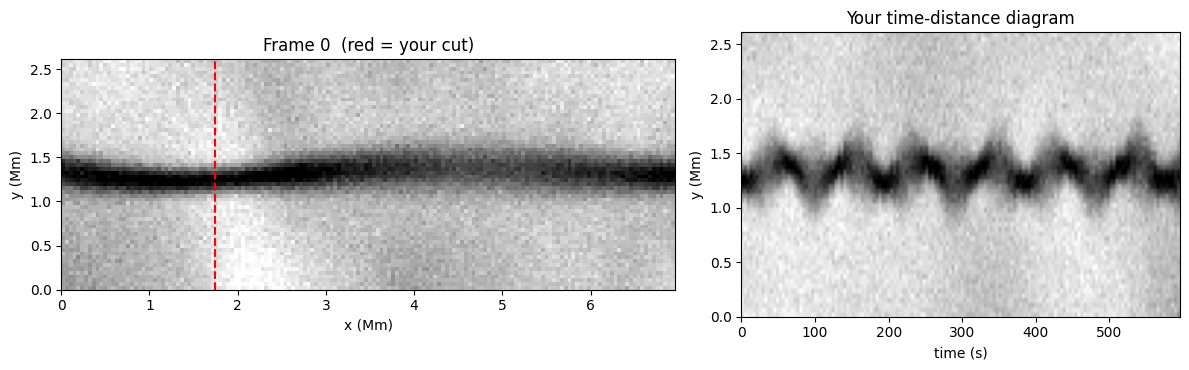

   figure -> figures/1_data.png


In [6]:
tl.plot_td(c, td, xc)


**BLOCK 2** — TASK: read your diagram (figures/1_data.png):  
count the crests of the dark band in the 600 s -> period P = 600 / n.  
Estimate how far the band moves up and down (in pixels, then km).  
-> results to create: n_crests, P_by_eye

In [7]:
# >>> YOUR TURN
n_crests = 6                                        # what you counted
P_by_eye = c.nt * c.dt / n_crests
print(f"Period by eye: {P_by_eye:.0f} s")
# <<<

Period by eye: 100 s


*Pictures (nothing to do)*

In [8]:
tl.gif_movie(c)
tl.gif_td_build(c, td, xc)

Output hidden; open in https://colab.research.google.com to view.

## EXERCISE 2 -- The kink: how far and how often does the fibril shake?

```
(talk block 3, Morton Fig. 4 and Fig. 3)

At every time, the fibril is a dark VALLEY in the brightness profile. Fit it with
an upside-down bell (a Gaussian):  I(y) = I0 - A exp[-(y - y0)^2 / (2 sigma^2)]
The CENTRE y0(t) is the kink. A sine fit to y0(t) gives the period P and the
amplitude xi, and from them the transverse velocity  v = 2 pi xi / P.
```

In [9]:
import numpy as np
import tools as tl

c = tl.Cube()
xc = tl.choose_cut(CUT, c.nx)
td = tl.ref_build_td(c.data, xc)                    # (your exercise 1)

Cube (t, y, x) = (150, 60, 160); cadence 4 s; pixel 43.5 km; field 2.6 x 7.0 Mm; duration 600 s
Your cut: column x = 40


**BLOCK 1** — TASK: write the model of a dark fibril profile (the Gaussian valley).  
-> results to create: function valley(y, I0, A, y0, sigma)

In [10]:
# >>> YOUR TURN
def valley(y, I0, A, y0, sigma):
    return I0 - A * np.exp(-(y - y0) ** 2 / (2 * sigma ** 2))
# <<<

**BLOCK 2** — TASK: fit the valley at every time step and keep the centre y0 and sigma.  
tl.fit_curve(model, x, y, first_guess) returns the best parameters.  
First guess: [median of profile, 0.3, tl.darkest_pixel(profile), 3.5]  
-> results to create: arrays centre, sigma

In [11]:
# >>> YOUR TURN
centre, sigma = np.empty(c.nt), np.empty(c.nt)
for k in range(c.nt):
    profile = td[:, k]
    I0, A, y0, s = tl.fit_curve(valley, c.y, profile,
                                [np.median(profile), 0.3, tl.darkest_pixel(profile), 3.5])
    centre[k], sigma[k] = y0, abs(s)
# <<<

**BLOCK 3** — TASK: fit a sine to centre(t) -> period P (s) and amplitude xi (km),  
then the transverse velocity v = 2 pi xi / P (km/s).  
tl.fit_sine(t, series) returns a dict with "P" (s) and "A" (pixels).  
-> results to create: fit, P, xi_km, v

In [12]:
# >>> YOUR TURN
fit = tl.fit_sine(c.t, centre)
P = fit["P"]
xi_km = fit["A"] * c.pix_km
v = 2 * np.pi * xi_km / P
# <<<

tl.report(f"KINK at x = {c.km(xc) / 1e3:.2f} Mm", [
    ("period P", P, "s"), ("amplitude xi", xi_km, "km"),
    ("velocity v = 2 pi xi / P", v, "km/s", "(Morton 2012: 6.4 +- 2.8)")])


===== KINK at x = 1.74 Mm =====
  period P                                  96 s     
  amplitude xi                            89.8 km    
  velocity v = 2 pi xi / P                5.88 km/s    (Morton 2012: 6.4 +- 2.8)


*Pictures (nothing to do)*

In [13]:
tl.plot_kink(c, td, centre, fit, v)
tl.gif_kink_fit(c, td, centre, sigma)

Output hidden; open in https://colab.research.google.com to view.

## EXERCISE 3 -- The sausage: does the fibril breathe?  (talk block 3, Morton Fig. 4c)

```
The same Gaussian fit gives two more numbers at every time:
  sigma(t) -> the WIDTH  (FWHM = 2.355 sigma)       A(t) -> the DEPTH (darkness)
If it is a sausage wave, width and darkness go in ANTIPHASE: when the tube
widens, the gas thins out and looks less dark.
Morton: "out-of-phase behaviour is typical of fast MHD sausage waves".
```

In [14]:
import numpy as np
import tools as tl

c = tl.Cube()
xc = tl.choose_cut(CUT, c.nx)
td = tl.ref_build_td(c.data, xc)                     # (your exercise 1)
centre, sigma, depth = tl.ref_fit_profiles(td)       # (your exercise 2, now with the depth too)

Cube (t, y, x) = (150, 60, 160); cadence 4 s; pixel 43.5 km; field 2.6 x 7.0 Mm; duration 600 s
Your cut: column x = 40


**BLOCK 1** — TASK: convert sigma to the full width at half maximum in km: FWHM = 2.355 sigma.  
Fit a sine to the width -> period and relative width change (%).  
-> results to create: fwhm_km, fit, P, width_change_pct

In [15]:
# >>> YOUR TURN
fwhm_km = 2.355 * sigma * c.pix_km
fit = tl.fit_sine(c.t, sigma)
P = fit["P"]
width_change_pct = 100 * fit["A"] / fit["mean"]
# <<<

**BLOCK 2** — TASK: are width and darkness in antiphase? Compute their correlation  
coefficient (np.corrcoef). Close to -1 means antiphase -> sausage.  
Tip: remove slow trends first (subtract a straight-line fit, np.polyfit).  
-> results to create: r

In [16]:
# >>> YOUR TURN
def detrend(s):
    return s - np.polyval(np.polyfit(c.t, s, 1), c.t)
r = np.corrcoef(detrend(sigma), detrend(depth))[0, 1]
# <<<

tl.report(f"SAUSAGE at x = {c.km(xc) / 1e3:.2f} Mm", [
    ("period P", P, "s"), ("mean FWHM", fwhm_km.mean(), "km", "(Morton 2012: 360 +- 120)"),
    ("width change", width_change_pct, "%"),
    ("corr(width, darkness)", r, "", "ANTIPHASE -> sausage" if r < -0.3 else "inconclusive")])


===== SAUSAGE at x = 1.74 Mm =====
  period P                                63.9 s     
  mean FWHM                                344 km      (Morton 2012: 360 +- 120)
  width change                            34.4 %     
  corr(width, darkness)                 -0.958         ANTIPHASE -> sausage


*Pictures (nothing to do)*

In [17]:
tl.plot_sausage(c, fwhm_km, depth, fit, r)
tl.gif_sausage_fit(c, td, centre, sigma, depth)

Output hidden; open in https://colab.research.google.com to view.

## EXERCISE 4 -- Propagation: does the wave travel? How fast?  (talk block 3, Morton Fig. 5)

```
The most important one!

Put several cuts along the fibril. If the wave travels, the same crest reaches
the far cuts LATER (like a stadium wave):   delay = distance / v_phase.
With many cuts, the PHASE of the oscillation drops along a straight line with x:
    phase(x) = phase0 - k x      ->      v_phase = omega / k = (2 pi / P) / k
For the kink, v_phase is the kink speed c_k (used for seismology and energy).
```

In [18]:
from types import SimpleNamespace
args = SimpleNamespace(cuts=CUTS, zeta=ZETA)
import numpy as np
import tools as tl

c = tl.Cube()
cuts = tl.choose_cuts(args.cuts, c.nx)
r = tl.ref_measure_cuts(c, cuts)        # centre and width series at every cut (exercises 2-3)
x_km = r["x_km"]
P_k, P_s = r["P_kink"], r["P_sausage"]

Cube (t, y, x) = (150, 60, 160); cadence 4 s; pixel 43.5 km; field 2.6 x 7.0 Mm; duration 600 s
Your cuts (columns): [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150]


**BLOCK 1** — TASK: at every cut, get the phase of the kink (from r["centres"][j]) and of the  
sausage (from r["widths"][j]). tl.phase_amplitude(t, series, P) -> (phase, amplitude).  
Then np.unwrap the phases (removes 2 pi jumps).  
-> results to create: phase_k, phase_s

In [19]:
# >>> YOUR TURN
phase_k = np.unwrap([tl.phase_amplitude(c.t, s, P_k)[0] for s in r["centres"]])
phase_s = np.unwrap([tl.phase_amplitude(c.t, s, P_s)[0] for s in r["widths"]])
# <<<

**BLOCK 2** — TASK: fit a straight line phase(x) (np.polyfit(x_km, phase, 1)); its slope is -k.  
Phase speed v = (2 pi / P) / k  in km/s, for kink and sausage.  
-> results to create: v_k, v_s

In [20]:
# >>> YOUR TURN
k_k = -np.polyfit(x_km, phase_k, 1)[0]
k_s = -np.polyfit(x_km, phase_s, 1)[0]
v_k = 2 * np.pi / P_k / k_k
v_s = 2 * np.pi / P_s / k_s
# <<<

tl.report("PROPAGATION", [
    ("kink phase speed c_k", v_k, "km/s", f"(delay {1e3 / v_k:.1f} s per Mm)"),
    ("sausage phase speed", v_s, "km/s", f"(delay {1e3 / v_s:.1f} s per Mm)")])
# QUESTION: which one is faster? Why is the sausage called a "fast" mode?


===== PROPAGATION =====
  kink phase speed c_k                    60.3 km/s    (delay 16.6 s per Mm)
  sausage phase speed                     99.9 km/s    (delay 10.0 s per Mm)


*Pictures (nothing to do)*

In [21]:
tl.plot_phase_vs_x(x_km, phase_k, phase_s, v_k, v_s)
tl.plot_and_gif_propagation(c, r, v_k)

Output hidden; open in https://colab.research.google.com to view.

## EXERCISE 5 -- Damping: does the wave lose strength as it travels?  (talk block 4)

```
Measure the kink amplitude at each cut and fit
    A(x) = A0 exp(-x / L_D)   ->   ln A = ln A0 - x / L_D   (a straight line!)
L_D = damping length (every L_D the amplitude drops to 37 %).
Compare with the wavelength lambda = c_k P.

Seismology of the tube boundary: if resonant absorption is responsible
(Terradas, Goossens & Verth 2010, A&A 524, A23):
    L_D / lambda = (2/pi) (R/l) (zeta + 1)/(zeta - 1),     zeta = rho_i / rho_e
Assume zeta and solve for the boundary thickness l/R (it must be between 0 and 2).
```

In [22]:
from types import SimpleNamespace
args = SimpleNamespace(cuts=CUTS, zeta=ZETA)
import numpy as np
import tools as tl

c = tl.Cube()
cuts = tl.choose_cuts(args.cuts, c.nx)
r = tl.ref_measure_cuts(c, cuts)
x_km, P_k = r["x_km"], r["P_kink"]
phases = np.unwrap([tl.phase_amplitude(c.t, s, P_k)[0] for s in r["centres"]])
c_k = 2 * np.pi / P_k / -np.polyfit(x_km, phases, 1)[0]          # (your exercise 4)

Cube (t, y, x) = (150, 60, 160); cadence 4 s; pixel 43.5 km; field 2.6 x 7.0 Mm; duration 600 s
Your cuts (columns): [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150]


**BLOCK 1** — TASK: kink amplitude (km) at every cut, and the sausage width change (%).  
tl.phase_amplitude(t, series, P) -> (phase, amplitude in pixels).  
-> results to create: A_k, width_pct

In [23]:
# >>> YOUR TURN
A_k = np.array([tl.phase_amplitude(c.t, s, P_k)[1] for s in r["centres"]]) * c.pix_km
width_pct = np.array([100 * tl.phase_amplitude(c.t, s, r["P_sausage"])[1] / s.mean()
                      for s in r["widths"]])
# <<<

**BLOCK 2** — TASK: fit a straight line to ln(A_k) vs x  ->  A0 and L_D.  Then L_D / lambda.  
-> results to create: L_D, A0, lam

In [24]:
# >>> YOUR TURN
slope, intercept = np.polyfit(x_km, np.log(A_k), 1)
L_D, A0 = -1 / slope, np.exp(intercept)
lam = c_k * P_k
# <<<

**BLOCK 3** — TASK: seismology. Solve the Terradas formula for l/R, assuming zeta = args.zeta.  
-> results to create: zeta, l_over_R

In [25]:
from types import SimpleNamespace
args = SimpleNamespace(cuts=CUTS, zeta=ZETA)
# >>> YOUR TURN
zeta = args.zeta
l_over_R = (2 / np.pi) * (lam / L_D) * (zeta + 1) / (zeta - 1)
# <<<

tl.report("DAMPING", [
    ("kink A0", A0, "km"), ("damping length L_D", L_D, "km"), ("wavelength lambda", lam, "km"),
    ("L_D / lambda", L_D / lam, ""), (f"boundary l/R (zeta = {zeta:g})", l_over_R, "",
                                       "impossible (>2)!" if l_over_R > 2 else ""),
    ("energy left at last cut", 100 * np.exp(-2 * x_km[-1] / L_D), "%"),
    ("sausage width change (mean)", width_pct.mean(), "%", "does it fade?")])


===== DAMPING =====
  kink A0                                  125 km    
  damping length L_D                  5.34e+03 km    
  wavelength lambda                   5.77e+03 km    
  L_D / lambda                           0.925       
  boundary l/R (zeta = 3)                 1.38         
  energy left at last cut                  8.7 %     
  sausage width change (mean)             34.1 %       does it fade?


*Pictures (nothing to do)*

In [26]:
tl.plot_amplitude_vs_x(x_km, A_k, A0, L_D, lam, width_pct)
tl.gif_damping(c, A0, L_D, np.mean(r["centres"]))
tl.gif_compare_damping()

Output hidden; open in https://colab.research.google.com to view.

## EXERCISE 6 -- How much energy does the kink carry? "Before" and "after" Tom

```
(Tom Van Doorsselaere).  Talk block 4: waves and heating.

BEFORE (naive "bulk Alfven" estimate; De Pontieu+ 2007, McIntosh+ 2011, Morton+ 2012):
    F_before = 1/2 rho_i v^2 c_k        (as if the WHOLE volume were dense, oscillating gas)
AFTER (Goossens+ 2013, ApJ 768, 191; Van Doorsselaere+ 2014, ApJ 795, 18, eq. 19):
    F_after  = 1/2 f (rho_i + rho_e) v^2 c_k = F_before * f (1 + 1/zeta)
  f = FILLING FACTOR (fraction of the area covered by tubes); the outside gas moves too.
  Valid for thin tubes and small f.
Why it matters: the naive value can be 10-50 times too large (Goossens+ 2013).
Why sometimes less: fibrils are packed (large f), density is uncertain by ~10x,
and observed velocities are underestimated (which pushes the other way).
```

In [27]:
from types import SimpleNamespace
args = SimpleNamespace(cuts=CUTS, zeta=ZETA)
import numpy as np
import tools as tl

zeta = args.zeta
RHO = (1e-10, 1e-9)                       # kg/m^3, typical range for a fibril
c = tl.Cube()
cuts = tl.choose_cuts(args.cuts, c.nx)
r = tl.ref_measure_cuts(c, cuts)
x_km, P_k = r["x_km"], r["P_kink"]
ph_amp = [tl.phase_amplitude(c.t, s, P_k) for s in r["centres"]]
c_k = 2 * np.pi / P_k / -np.polyfit(x_km, np.unwrap([p for p, a in ph_amp]), 1)[0]  # (exercise 4)
A_k = np.array([a for p, a in ph_amp]) * c.pix_km                                    # (exercise 5)
slope, icpt = np.polyfit(x_km, np.log(A_k), 1); L_D, A0 = -1 / slope, np.exp(icpt)   # (exercise 5)

Cube (t, y, x) = (150, 60, 160); cadence 4 s; pixel 43.5 km; field 2.6 x 7.0 Mm; duration 600 s
Your cuts (columns): [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150]


**BLOCK 1** — TASK: transverse velocity at every cut, v = 2 pi A / P  (km/s).  
-> results to create: v

In [28]:
# >>> YOUR TURN
v = 2 * np.pi * A_k / P_k
# <<<

**BLOCK 2** — TASK: measure the filling factor f from the data: the fraction of pixels of the  
time-averaged image (c.data.mean(axis=0)) that are "inside" the fibril,  
e.g. darker than half of the maximum darkness below the background (median).  
-> results to create: f

In [29]:
# >>> YOUR TURN
img = c.data.mean(axis=0)
darkness = np.median(img) - img
f = np.mean(darkness > 0.5 * darkness.max())
# <<<

**BLOCK 3** — TASK: the two energy fluxes in W/m^2 (convert km/s to m/s!).  
-> results to create: functions F_before(rho_i, v_kms), F_after(rho_i, v_kms)

In [30]:
# >>> YOUR TURN
def F_before(rho_i, v_kms):
    return 0.5 * rho_i * (v_kms * 1e3) ** 2 * (c_k * 1e3)

def F_after(rho_i, v_kms):
    return 0.5 * f * (rho_i + rho_i / zeta) * (v_kms * 1e3) ** 2 * (c_k * 1e3)
# <<<

**BLOCK 4** — TASK: how much flux is lost between the first and the last cut (heats the gas)?  
-> results to create: lost_before, lost_after

In [31]:
# >>> YOUR TURN
lost_before = [F_before(rho, v[0]) - F_before(rho, v[-1]) for rho in RHO]
lost_after = [F_after(rho, v[0]) - F_after(rho, v[-1]) for rho in RHO]
# <<<

ratio = F_after(1, 1) / F_before(1, 1)
tl.report("KINK ENERGY", [
    ("phase speed c_k", c_k, "km/s"), ("velocity first / last cut", f"{v[0]:.1f}/{v[-1]:.1f}", "km/s"),
    ("filling factor f", f, ""), ("F_after / F_before", ratio, "", f"naive is x{1 / ratio:.0f} too large"),
    ("F_before at first cut", f"{F_before(RHO[0], v[0]):.0f}-{F_before(RHO[1], v[0]):.0f}", "W/m2"),
    ("F_after  at first cut", f"{F_after(RHO[0], v[0]):.0f}-{F_after(RHO[1], v[0]):.0f}", "W/m2"),
    ("lost along the way, before", f"{lost_before[0]:.0f}-{lost_before[1]:.0f}", "W/m2"),
    ("lost along the way, after", f"{lost_after[0]:.0f}-{lost_after[1]:.0f}", "W/m2"),
    ("NEEDED: quiet-Sun chromosphere", 4000, "W/m2", "(Withbroe & Noyes 1977)"),
    ("NEEDED: quiet-Sun corona", 300, "W/m2"),
    ("Morton 2012 (naive), kink", 4300, "W/m2")])


===== KINK ENERGY =====
  phase speed c_k                         60.3 km/s  
  velocity first / last cut            7.9/2.4 km/s  
  filling factor f                       0.119       
  F_after / F_before                     0.158         naive is x6 too large
  F_before at first cut               187-1874 W/m2  
  F_after  at first cut                 30-296 W/m2  
  lost along the way, before          170-1704 W/m2  
  lost along the way, after             27-269 W/m2  
  NEEDED: quiet-Sun chromosphere         4e+03 W/m2    (Withbroe & Noyes 1977)
  NEEDED: quiet-Sun corona                 300 W/m2  
  Morton 2012 (naive), kink            4.3e+03 W/m2  


*Pictures (nothing to do)*

In [32]:
v_of_x = lambda xx: 2 * np.pi * A0 * np.exp(-xx / L_D) / P_k
tl.plot_energy(x_km, lambda rho, xx: F_before(rho, v_of_x(xx)), lambda rho, xx: F_after(rho, v_of_x(xx)), RHO,
               f"Kink: before and after Van Doorsselaere (f = {f:.2f}, ζ = {zeta:g}: ÷{1 / ratio:.0f})"
               f"   ·   drops as exp(−2x/L_D), L_D = {L_D / 1e3:.1f} Mm")
tl.gif_energy(c, A0, L_D, P_k, c_k, np.sqrt(RHO[0] * RHO[1]), ratio)

Output hidden; open in https://colab.research.google.com to view.